# Card Fraud Triage - Phase 1
**Team T011, Section A, Project 26**

## What are we making?
A program that puts unusual card transactions into a queue for a person to review.

We teach the program what **legitimate transactions** look like. Then we give it later transactions containing both legitimate purchases and fraud. It gives each transaction a score. A larger score means “this looks less usual.”

Our model is a **Gaussian Mixture Model**, shortened to **GMM**. Phase 1 uses this machine-learning model. The autoencoder belongs to Phase 2.

## How to read this notebook
Read one numbered step, run its code, and read the explanation below it. All analysis code appears here. You do not need to open another Python file.

The route is: **read data, clean it, split it, understand it, prepare inputs, fit GMM, set cutoffs, check results**.

A transaction being unusual does not prove it is fraud.

## 1. Import the tools
**What we do:** Load the Python libraries we will use.

**Why:** pandas handles tables, NumPy handles numbers, matplotlib draws charts, and scikit-learn provides the scaler and GMM. `Path` handles folders. `Image` and `display` show saved charts and tables.

An `import` makes a library available. `as pd`, `as np`, and `as plt` are short names, so later code is easier to read.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import precision_recall_curve, auc, confusion_matrix, ConfusionMatrixDisplay

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

**What the last two lines mean:** Create folders for charts and results. `exist_ok=True` means it is fine if the folder already exists. These lines do not train a model.

## 2. Read the transaction table
**What we do:** Read the recommended ULB/Worldline credit-card dataset.

**Why:** We need examples of real transactions to learn and evaluate patterns.

`read_csv` reads a CSV file into a table called `df`. `head()` shows the first five rows. If the CSV is missing, the next cell downloads the public copy documented by TensorFlow. If you already have it, no download occurs.

In [2]:
data_file = Path("data/raw/creditcard.csv")

if not data_file.exists():
    from urllib.request import urlretrieve
    data_file.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv", data_file)

df = pd.read_csv(data_file)
print("Rows:", len(df), " Columns:", len(df.columns))
display(df.head())

Rows: 284807  Columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### What do the columns mean?
| Column | Simple meaning | How we use it |
|---|---|---|
| Time | Seconds since the first transaction | Put earlier transactions before later ones |
| V1 to V28 | Numerical features hidden by the dataset provider for privacy | Inputs to the GMM |
| Amount | Transaction amount in EUR | Make a less spread-out amount input |
| Class | The correct answer: 0 means legitimate, 1 means fraud | Select legitimate training rows and check results |

A **row** is one transaction. A **feature** is one input describing that transaction. A **label** is the correct answer. We cannot give business meanings to V1-V28 because the original meanings are hidden.

The original file has **284,807 transactions and 492 frauds**. Do not confuse a column called `Class` with a model input.

The provider used **PCA**, which replaces original variables with new numerical combinations. We use its supplied V1-V28 columns and do not run another PCA.

## 3. Check and clean the data
**What we do:** Count missing values and exact repeated rows, then keep the first copy of each exact row.

**Why:** Missing numbers can break model fitting. Exact repeated records can make one observation count several times.

`isna()` finds missing cells. `sum().sum()` adds their count across the whole table. `duplicated()` marks exact repeats. `drop_duplicates()` keeps the first copy. `sort_values("Time")` puts transactions into time order.

**Cleaning assumption:** There is no transaction ID, so we cannot prove that identical rows represent the same real purchase. We document our decision to remove exact repeated records.

In [3]:
raw_rows = len(df)
raw_frauds = int(df["Class"].sum())
missing_cells = int(df.isna().sum().sum())
repeated_rows = int(df.duplicated().sum())

print("Missing cells:", missing_cells)
print("Exact repeated rows:", repeated_rows)
assert missing_cells == 0, "Inspect missing values before continuing."
assert np.isfinite(df.to_numpy()).all(), "Inspect non-finite numbers before continuing."
assert set(df["Class"].unique()) == {0, 1}, "Class must use 0 and 1."

df = df.sort_values("Time", kind="stable").drop_duplicates().copy()
print("After cleaning:", len(df), "transactions and", int(df["Class"].sum()), "frauds")

Missing cells: 0
Exact repeated rows: 1081
After cleaning: 283726 transactions and 473 frauds


**How to read the output:** There are no missing cells. We remove **1,081 exact repeated rows**. Nineteen of those repeated rows have a fraud label. The cleaned data therefore contains **283,726 transactions and 473 frauds**.

`assert` is a check: it stops execution with a message if a required condition is false. `copy()` gives us a separate table to work with. We keep large amounts and unusual values because unusual transactions are the subject of this project.

## 4. Make three time periods
**What we do:** Use roughly the first 60% for training, the next 20% for validation, and the last 20% for testing.

**Why we need three sets:**
- **Training:** teach the model normal patterns.
- **Validation:** decide how unusual a transaction must be before we create an alert.
- **Test:** check the choices on later transactions.

We split in time order because future transactions should not teach a model that is meant to evaluate the future. The two cutoff times keep transactions with the same timestamp together.

`iloc` reads a row by its position. A condition such as `df["Time"] < train_end` selects rows before that time.

In [4]:
train_end = df["Time"].iloc[int(0.60 * len(df))]
validation_end = df["Time"].iloc[int(0.80 * len(df))]

train = df[df["Time"] < train_end].copy()
validation = df[(df["Time"] >= train_end) & (df["Time"] < validation_end)].copy()
test = df[df["Time"] >= validation_end].copy()

assert train["Time"].max() < validation["Time"].min()
assert validation["Time"].max() < test["Time"].min()

split_table = pd.DataFrame({
    "Set": ["Training", "Validation", "Test"],
    "Transactions": [len(train), len(validation), len(test)],
    "Frauds": [int(train["Class"].sum()), int(validation["Class"].sum()), int(test["Class"].sum())]
})
split_table["Legitimate"] = split_table["Transactions"] - split_table["Frauds"]
split_table["Fraud rate (%)"] = 100 * split_table["Frauds"] / split_table["Transactions"]
display(split_table)

,Set,Transactions,Frauds,Legitimate,Fraud rate (%)
0,Training,170235,342,169893,0.200899
1,Validation,56745,57,56688,0.100449
2,Test,56746,74,56672,0.130406


**How to read the table:** Training contains 342 frauds, validation 57, and test 74. **We will remove the training frauds before fitting the model.** Validation and test keep both classes so we can measure mistakes.

**Fraud rate**, also called **base rate**, means fraud transactions divided by all transactions in that set. Reporting these counts does not use test labels to choose the model.

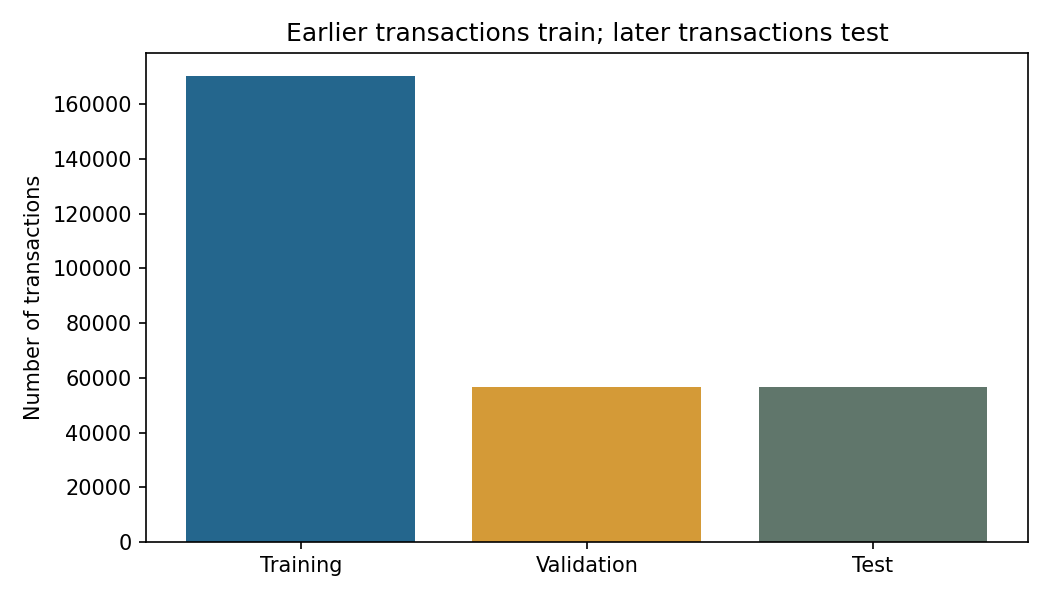

In [5]:
plt.figure(figsize=(7, 4))
plt.bar(split_table["Set"], split_table["Transactions"], color=["#24668d", "#d49a37", "#60766b"])
plt.ylabel("Number of transactions")
plt.title("Earlier transactions train; later transactions test")
plt.tight_layout()
plt.savefig("figures/01_split.png", dpi=150)
display(Image(filename="figures/01_split.png", width=800))
plt.close()

**Chart explanation:** The taller training bar means we use more examples to learn normal patterns. The two smaller bars provide separate periods for choosing the alert cutoff and checking final results.

## 5. EDA: understand the training data
**EDA means Exploratory Data Analysis.** It means using counts and charts to understand the data before fitting the model. We explore training data, so future test examples do not guide our feature decisions.

### 5.1 How rare is fraud?
We count legitimate and fraud transactions separately. `value_counts()` counts each label. `reindex([0, 1])` puts legitimate first and fraud second.

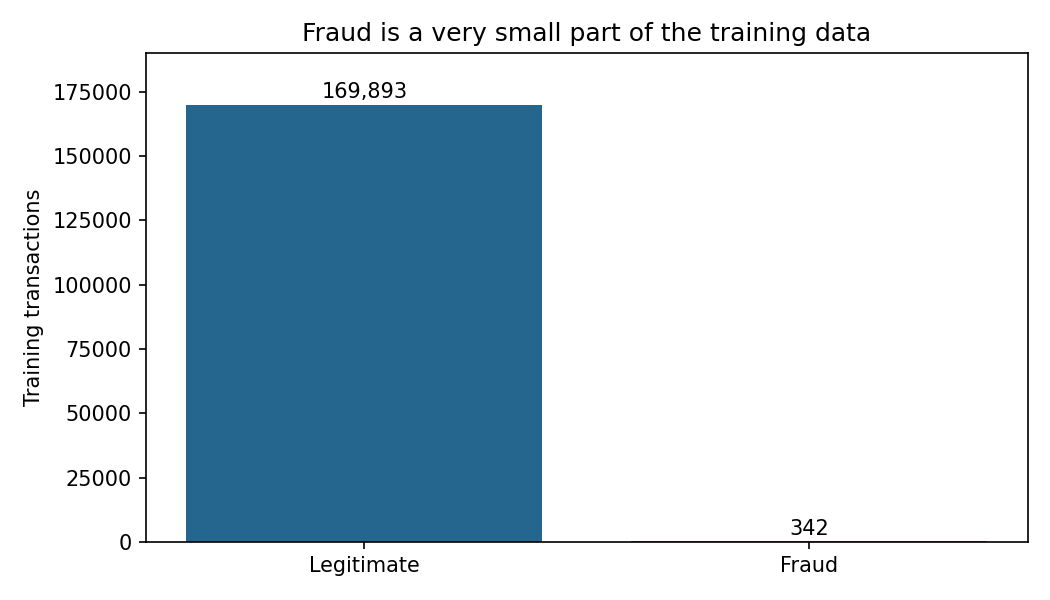

In [6]:
class_counts = train["Class"].value_counts().reindex([0, 1])
plt.figure(figsize=(7, 4))
plt.bar(["Legitimate", "Fraud"], class_counts, color=["#24668d", "#c44945"])
for position, count in enumerate(class_counts):
    plt.text(position, count + 2500, f"{count:,}", ha="center")
plt.ylim(0, 190000)
plt.ylabel("Training transactions")
plt.title("Fraud is a very small part of the training data")
plt.tight_layout()
plt.savefig("figures/02_class_balance.png", dpi=150)
display(Image(filename="figures/02_class_balance.png", width=800))
plt.close()

**Chart explanation:** The fraud bar is tiny because there are only 342 training frauds, compared with 169,893 legitimate transactions. Its small height is the actual imbalance.

**Why accuracy is misleading:** If we said “legitimate” for every test transaction, about 99.87% of answers would be correct, but we would catch **zero frauds**. We will measure fraud found and false alerts instead.

### 5.2 Why change Amount?
Most amounts are small, but a few are very large. This is a **long right tail**. We compare raw Amount with `log(1 + Amount)`.

The log makes large values less spread out. It keeps their order and accepts zero. For example: 0 becomes 0, 9 becomes about 2.30, and 999 becomes about 6.91. We are changing the numerical scale, not deleting expensive transactions.

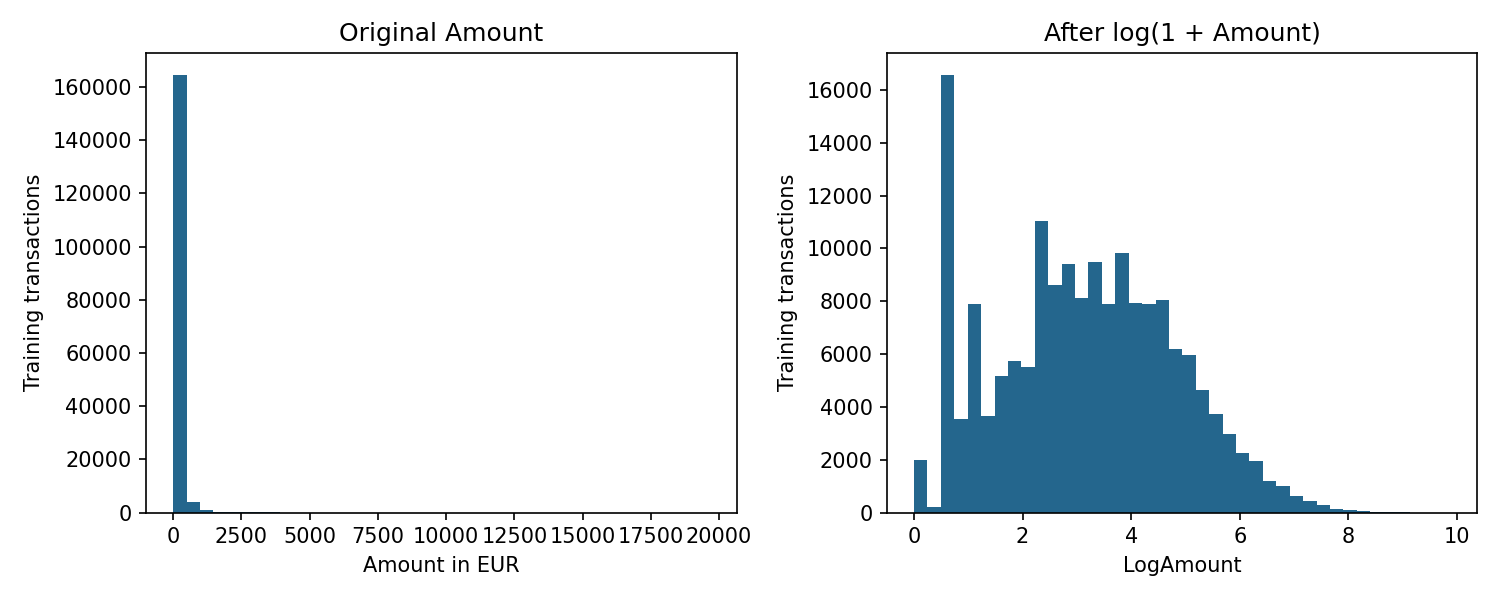

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(train["Amount"], bins=40, color="#24668d")
axes[0].set_title("Original Amount")
axes[0].set_xlabel("Amount in EUR")
axes[0].set_ylabel("Training transactions")

axes[1].hist(np.log1p(train["Amount"]), bins=40, color="#24668d")
axes[1].set_title("After log(1 + Amount)")
axes[1].set_xlabel("LogAmount")
axes[1].set_ylabel("Training transactions")
plt.tight_layout()
plt.savefig("figures/03_amount.png", dpi=150)
display(Image(filename="figures/03_amount.png", width=800))
plt.close()

**Chart explanation:** The first chart packs many transactions near the left edge. The second spreads those values across a smaller numerical range, so their shape is easier to see.

**Plotting code:** `hist` groups values into ranges and counts how many fall in each range. `bins=40` means 40 ranges. The height shows transaction count. `subplots(1, 2)` places two charts next to each other. The last four lines of each chart save a picture, display it, and close the chart.

### 5.3 Does transaction volume change over time?
We divide Time by 3,600 because one hour has 3,600 seconds. `//` means divide and keep the whole-number part. `groupby` collects rows for each hour; `size` counts them.

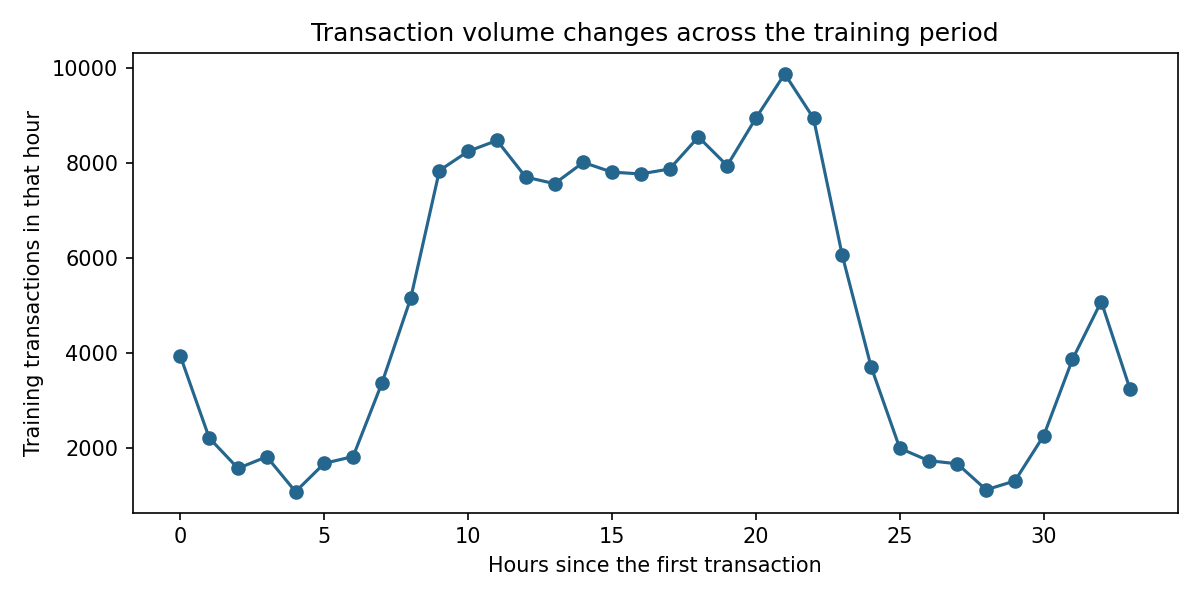

In [8]:
hourly_counts = train.groupby(train["Time"] // 3600).size()
plt.figure(figsize=(8, 4))
plt.plot(hourly_counts.index, hourly_counts.values, marker="o", color="#24668d")
plt.xlabel("Hours since the first transaction")
plt.ylabel("Training transactions in that hour")
plt.title("Transaction volume changes across the training period")
plt.tight_layout()
plt.savefig("figures/04_time.png", dpi=150)
display(Image(filename="figures/04_time.png", width=800))
plt.close()

**Chart explanation:** Some hours contain more transactions than others. We have a short historical recording, so this chart does not prove a pattern that will always repeat. Time remains a splitting tool, not a model input.

### 5.4 Do the two classes overlap?
We show V1 and V2 as a simple two-feature picture. Each dot is one training transaction.

To keep the picture readable, we draw 5,000 legitimate examples and all training frauds. **This sampling affects only the chart. The GMM will still train on every legitimate training row.**

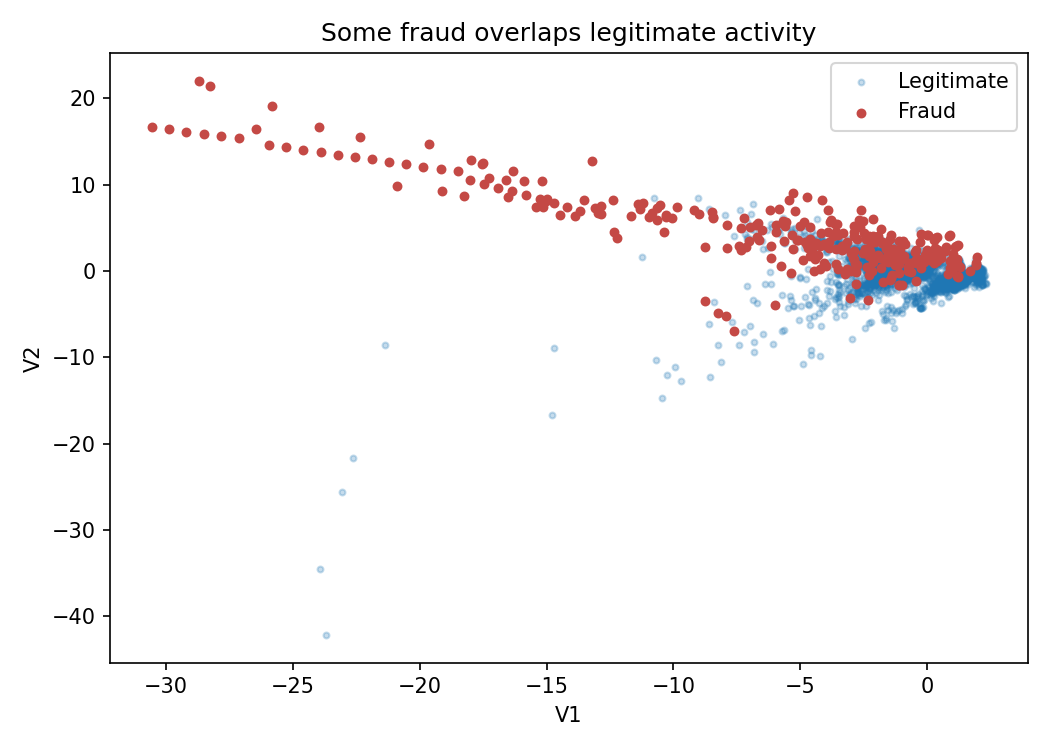

In [9]:
normal_picture = train[train["Class"] == 0].sample(5000, random_state=42)
fraud_picture = train[train["Class"] == 1]

plt.figure(figsize=(7, 5))
plt.scatter(normal_picture["V1"], normal_picture["V2"], s=8, alpha=0.25, label="Legitimate")
plt.scatter(fraud_picture["V1"], fraud_picture["V2"], s=14, color="#c44945", label="Fraud")
plt.xlabel("V1")
plt.ylabel("V2")
plt.title("Some fraud overlaps legitimate activity")
plt.legend()
plt.tight_layout()
plt.savefig("figures/05_overlap.png", dpi=150)
display(Image(filename="figures/05_overlap.png", width=800))
plt.close()

**Chart explanation:** Some fraud points fall near legitimate points. A simple rule on V1 and V2 cannot perfectly separate them. The GMM uses all 29 inputs, but overlap can still produce missed fraud and false alerts. V1 and V2 are anonymous numerical features; we do not know their business meanings.

## 6. Prepare the 29 inputs
**What we do:** Create LogAmount, keep V1-V28, and select only legitimate training rows.

**Why:** We want the GMM to learn legitimate behavior. We keep Class out of the input because it is the answer we later check. Time has already done its job of ordering the periods.

The list comprehension creates the names V1, V2, up to V28. Adding `["LogAmount"]` gives **29 input columns**. In pandas, `table[features]` selects those columns, while `table[condition]` selects rows.

In [10]:
train["LogAmount"] = np.log1p(train["Amount"])
validation["LogAmount"] = np.log1p(validation["Amount"])
test["LogAmount"] = np.log1p(test["Amount"])

features = ["V" + str(i) for i in range(1, 29)] + ["LogAmount"]
normal_train = train[train["Class"] == 0].copy()

X_train = normal_train[features]
X_validation = validation[features]
X_test = test[features]
y_test = test["Class"].to_numpy()

assert "Class" not in features and "Time" not in features
print("Training:", X_train.shape, " Validation:", X_validation.shape, " Test:", X_test.shape)

Training: (169893, 29)  Validation: (56745, 29)  Test: (56746, 29)


**How to read the output:** `(169893, 29)` means 169,893 legitimate training transactions, each described by 29 features. The 342 training frauds do not enter GMM fitting.

`X` means inputs. `y` means correct answers. `to_numpy()` turns the test-label column into a numerical array for later calculations.

We do use labels to select known legitimate training examples. The GMM itself receives only X, with no fraud targets. Calling the whole preparation completely label-free would be incorrect.

## 7. Scale the inputs
**What we do:** Use StandardScaler to put inputs on a common numerical scale.

**Why:** Columns can have different centers and spreads. Scaling gives the model more consistent numerical units.

For each column: **scaled value = (original value - training mean) / training standard deviation**.

`fit_transform` learns these numbers and applies them. `transform` applies the already learned numbers. We fit only on legitimate training rows. Fitting on future test data would let future information influence the model; this is called **data leakage**.

**Small example:** If a feature has training mean 100 and standard deviation 50, a value of 150 becomes `(150 - 100) / 50 = 1`. It is one training standard deviation above the mean. These are teaching numbers, not estimates from our data.

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

print("First three scaled inputs for the first training transaction:")
print(X_train_scaled[0, :3])
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-10)

First three scaled inputs for the first training transaction:
[-0.67390624 -0.06370234  1.58778996]


**How to read the output:** A value near 0 is near that feature's legitimate training average. A negative value is below it; a positive value is above it. A negative scaled value does not mean a negative purchase amount.

The last line checks that the transformed training columns are centered near zero. Scaling parameters stay fixed for validation and test.

## 8. Understand the GMM before training it
A **Gaussian** is a bell-shaped pattern with a center and a spread. A **mixture** combines several such patterns. This lets the model describe legitimate data that has several centers.

**K** means the number of Gaussian components. Components are mathematical groups, not verified customer categories.

The GMM learns with a repeated process called **EM**:
1. **E-step:** estimate how much each transaction belongs to each component.
2. **M-step:** use those estimated memberships to update component centers, spreads, and weights.

Repeat until the estimates change very little.

### Our small set of choices
| Code setting | Plain meaning | Why we use it |
|---|---|---|
| `n_components=k` | Try k Gaussian components | Compare 1, 2, 4 and 8 |
| `covariance_type="diag"` | Learn each input's spread separately inside a component | A smaller, faster baseline |
| `n_init=3` | Try three starting arrangements | Reduce dependence on one starting arrangement |
| `max_iter=200` | Allow up to 200 EM rounds per start | Give fitting a clear limit |
| `reg_covar=1e-6` | Add a tiny amount to estimated variances | Avoid a spread collapsing to zero |
| `random_state=42` | Fix the starting randomness | Help reproduce the run |

A diagonal covariance is an approximation: real inputs can still have relationships that it misses.

![Teaching illustration of one Gaussian and a two-component mixture](figures/gmm_teaching.png)

**Read the picture:** The left curve has one center. On the right, we add two weighted Gaussian curves to get the solid mixture curve. The illustration uses invented numbers only. Our real model uses 29 features and selects eight components. A two-feature picture cannot show all of those dimensions.

## 9. Fit four GMMs and choose K
**What we do:** Try K=1, 2, 4 and 8 on the same legitimate training inputs.

**How we choose:** AIC and BIC reward a better fit but penalize extra parameters. **Lower is better. We choose the smallest BIC.** We show AIC as an additional check; we do not switch between rules after seeing test results.

`fit` learns the model. `converged_` tells us whether the stopping rule was reached. The dictionaries store fitted models and their scores. The loop runs the same code once for each K.

In [12]:
models = {}
selection_rows = []

for k in [1, 2, 4, 8]:
    gmm = GaussianMixture(n_components=k, covariance_type="diag", n_init=3,
                          max_iter=200, reg_covar=1e-6, random_state=42)
    gmm.fit(X_train_scaled)
    assert gmm.converged_, "This GMM did not finish fitting. Inspect it before continuing."
    models[k] = gmm
    selection_rows.append({"K": k, "AIC": gmm.aic(X_train_scaled), "BIC": gmm.bic(X_train_scaled)})

selection = pd.DataFrame(selection_rows)
display(selection)

best_row = selection["BIC"].idxmin()
best_k = int(selection.loc[best_row, "K"])
model = models[best_k]
print("Chosen K:", best_k)

Chosen K: 8


,K,AIC,BIC
0,1,1.398204e+07,1.398263e+07
1,2,1.193484e+07,1.193601e+07
2,4,1.089440e+07,1.089676e+07
3,8,1.014018e+07,1.014492e+07


**Code explanation:** `idxmin()` finds the row with the smallest BIC. `loc[best_row, "K"]` reads K from that row. `models[best_k]` retrieves the corresponding fitted model, so we do not fit it again.

**Result:** K=8 wins among our four choices. We do not claim eight is the best among every possible K. A lower BIC means better legitimate-data fit with its penalty; it does not guarantee better fraud detection.

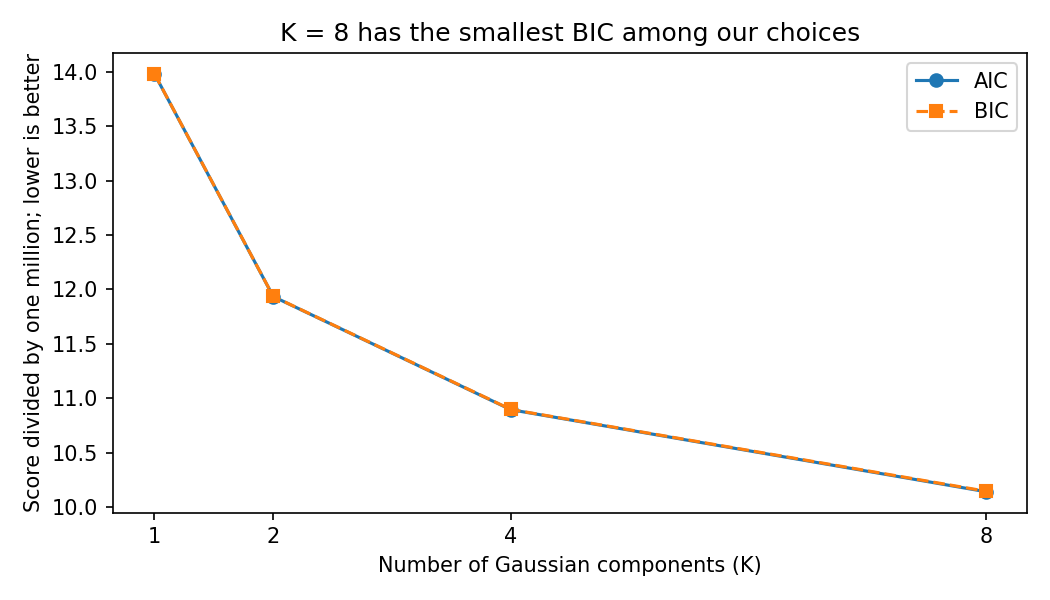

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(selection["K"], selection["AIC"] / 1000000, "o-", label="AIC")
plt.plot(selection["K"], selection["BIC"] / 1000000, "s--", label="BIC")
plt.xticks([1, 2, 4, 8])
plt.xlabel("Number of Gaussian components (K)")
plt.ylabel("Score divided by one million; lower is better")
plt.title("K = 8 has the smallest BIC among our choices")
plt.legend()
plt.tight_layout()
plt.savefig("figures/06_aic_bic.png", dpi=150)
display(Image(filename="figures/06_aic_bic.png", width=800))
plt.close()

**Chart explanation:** The scores decrease as K increases in this small grid. The AIC and BIC lines are very close because their penalties differ by much less than the total fit score. Eight is also the largest K tried; the chart does not show that improvement has stopped.

## 10. Turn density into an anomaly score
**Density** means how strongly the fitted model supports a transaction's location in the input space. A low-density transaction looks less typical of the legitimate training data.

We use: **anomaly score = -log(density)**.

`score_samples` already returns log density, one value per transaction. Putting a minus sign in front makes less usual transactions have **larger** scores.

For a numerical illustration: density 0.01 gives a score about 4.61; density 0.0001 gives about 9.21. The second is less usual under that model. These are teaching numbers, not scores taken from our dataset.

An anomaly score is **not a probability of fraud**. A continuous density can exceed one, so scores can also be negative.

In [14]:
validation_scores = -model.score_samples(X_validation_scaled)
normal_validation_scores = validation_scores[validation["Class"].to_numpy() == 0]

print("First five validation anomaly scores:")
print(validation_scores[:5])

First five validation anomaly scores:
[41.90428372 38.35735395 32.89847696 33.39453481 35.05359906]


**Code explanation:** The first line scores every validation transaction. The second keeps only scores whose validation label is 0. Those known legitimate examples will set our alert cutoff. We have not evaluated test performance yet.

## 11. Choose alert cutoffs using validation data
A **threshold** is a cutoff: create an alert if `score > threshold`.

A **false positive** is a legitimate transaction that receives an alert. A **false-positive rate (FPR)** is false alerts divided by all legitimate transactions.

We try three validation budgets:
- **0.1%:** about 1 false alert per 1,000 legitimate transactions.
- **0.5%:** about 5 per 1,000. This is our illustrative default.
- **1%:** about 10 per 1,000.

For 0.5%, choose the **99.5th percentile** of legitimate validation scores. A percentile is a position in a sorted list: most legitimate scores fall below this cutoff. `method="higher"` chooses an actual score conservatively, helping keep the observed validation false-alert rate within budget.

The default 0.5% is a classroom example chosen before test evaluation, not an operating target from a bank.

In [15]:
budgets = [0.001, 0.005, 0.01]
thresholds = {}

for budget in budgets:
    cutoff = np.percentile(normal_validation_scores, 100 * (1 - budget), method="higher")
    thresholds[budget] = float(cutoff)
    observed_fpr = np.mean(normal_validation_scores > cutoff)
    assert observed_fpr <= budget
    print(f"Budget {100*budget:.1f}%: cutoff {cutoff:.4f}, validation FPR {100*observed_fpr:.4f}%")

default_threshold = thresholds[0.005]
print("All choices are fixed. We can now evaluate the test period.")

Budget 0.1%: cutoff 112.9651, validation FPR 0.0988%
Budget 0.5%: cutoff 75.8942, validation FPR 0.4992%
Budget 1.0%: cutoff 68.9345, validation FPR 0.9984%
All choices are fixed. We can now evaluate the test period.


**How to read the output:** The default cutoff is about **75.8942**. A transaction with a score above it gets an alert; a score equal to it does not.

A validation budget controls the observed validation rate. Later test transactions can have a different rate because their patterns can differ. We keep the cutoff fixed rather than changing it to match the test labels.

`np.mean(normal_validation_scores > cutoff)` finds the fraction flagged: Python counts True as 1 and False as 0, so their average is the fraction of alerts.

## 12. Evaluate the later test period
**What we do:** Score the test transactions with the already chosen GMM and threshold.

**Why:** This checks how the fixed choices behave on later data. We do not use these results to choose K or change the threshold.

`predicted_fraud` contains True for an alert and False for no alert. The confusion matrix counts four outcomes:

| Name | Meaning |
|---|---|
| TN: true negative | Legitimate, no alert |
| FP: false positive | Legitimate, alert |
| FN: false negative | Fraud, no alert |
| TP: true positive | Fraud, alert |

In [16]:
test_scores = -model.score_samples(X_test_scaled)
predicted_fraud = test_scores > default_threshold

cm = confusion_matrix(y_test, predicted_fraud, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Legitimate with no alert (TN):", tn)
print("Legitimate with an alert (FP):", fp)
print("Fraud missed (FN):", fn)
print("Fraud found (TP):", tp)

Legitimate with no alert (TN): 56500
Legitimate with an alert (FP): 172
Fraud missed (FN): 37
Fraud found (TP): 37


**Code explanation:** `ravel()` reads the 2-by-2 matrix in row order: TN, FP, FN, TP.

**Our result:** We correctly leave 56,500 legitimate transactions unflagged, falsely alert on 172 legitimate transactions, miss 37 frauds, and find 37 frauds.

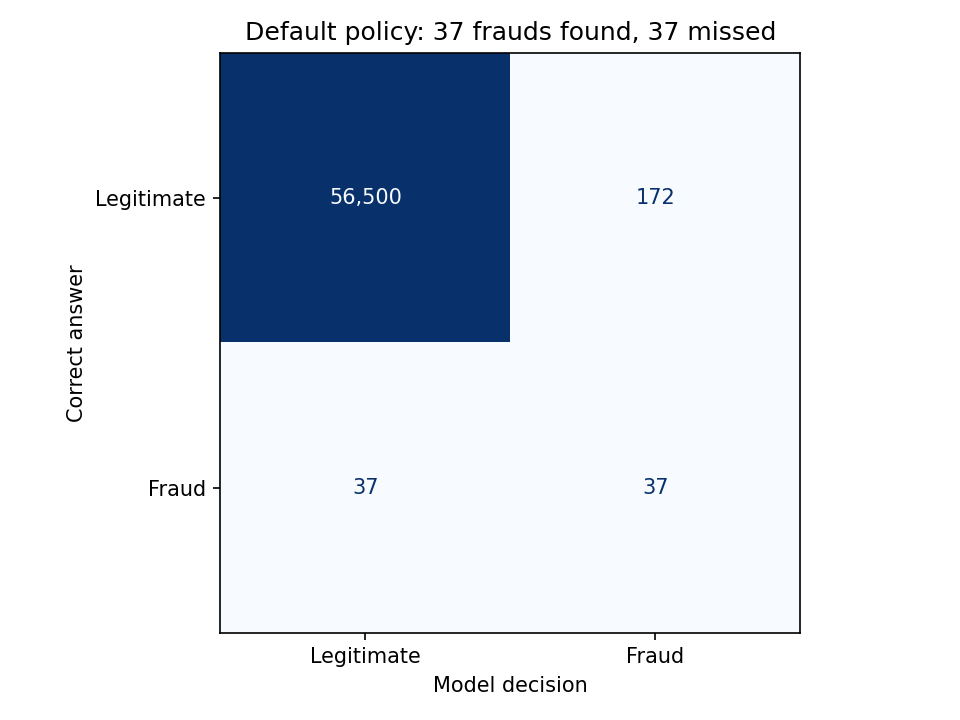

In [17]:
ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"]).plot(
    cmap="Blues", values_format=",d", colorbar=False)
plt.xlabel("Model decision")
plt.ylabel("Correct answer")
plt.title("Default policy: 37 frauds found, 37 missed")
plt.tight_layout()
plt.savefig("figures/07_confusion.png", dpi=150)
display(Image(filename="figures/07_confusion.png", width=800))
plt.close()

**Chart explanation:** Rows show the correct class; columns show the model's decision. The top-right box contains false alerts. The bottom-left box contains missed fraud. Read the printed counts, because the large legitimate count dominates the colors.

## 13. Calculate the useful measures
We need three questions answered:

1. **Recall:** Of all actual frauds, how many did we find? `TP / (TP + FN)`.
2. **Precision:** Of all alerts, how many were actually fraud? `TP / (TP + FP)`.
3. **FPR:** Of all legitimate transactions, how many did we disturb with an alert? `FP / (FP + TN)`.

These denominators are different. Precision uses **alerts**; FPR uses **legitimate transactions**.

In [18]:
recall_default = tp / (tp + fn)
precision_default = tp / (tp + fp)
fpr_default = fp / (fp + tn)

print(f"Recall: {tp}/{tp+fn} = {100*recall_default:.2f}%")
print(f"Precision: {tp}/{tp+fp} = {100*precision_default:.2f}%")
print(f"FPR: {fp}/{fp+tn} = {100*fpr_default:.4f}%")
print("Total transactions sent for review:", tp + fp)

Recall: 37/74 = 50.00%
Precision: 37/209 = 17.70%
FPR: 172/56672 = 0.3035%
Total transactions sent for review: 209


**Meaning of our result:**
- **50% recall:** we find half the 74 test frauds.
- **17.70% precision:** 37 of the 209 review alerts are fraud.
- **0.3035% test FPR:** 172 of the 56,672 legitimate test transactions receive an alert.

Most alerts are legitimate, and we miss half the fraud. State both facts in the viva.

## 14. See the effect of the three validation budgets
We now apply each **already fixed** validation cutoff to the same test period. This shows the cost of reviewing more transactions. It does not choose a new best policy from test results.

The loop repeats the same confusion-matrix calculations for each stored cutoff. Each dictionary becomes one table row.

In [19]:
policy_rows = []
for budget in budgets:
    alerts = test_scores > thresholds[budget]
    tn_policy, fp_policy, fn_policy, tp_policy = confusion_matrix(y_test, alerts, labels=[0, 1]).ravel()
    policy_rows.append({
        "Validation budget (%)": 100 * budget,
        "Test fraud found": int(tp_policy), "Test false alerts": int(fp_policy),
        "Test recall (%)": 100 * tp_policy / (tp_policy + fn_policy),
        "Test precision (%)": 100 * tp_policy / (tp_policy + fp_policy) if tp_policy + fp_policy else 0,
        "Test FPR (%)": 100 * fp_policy / (fp_policy + tn_policy)
    })
policy_table = pd.DataFrame(policy_rows)
display(policy_table.round(4))

,Validation budget (%),Test fraud found,Test false alerts,Test recall (%),Test precision (%),Test FPR (%)
0,0.1,6,39,8.1081,13.3333,0.0688
1,0.5,37,172,50.0000,17.7033,0.3035
2,1.0,52,381,70.2703,12.0092,0.6723


**Reading the table:** At the strict 0.1% budget we find 6 frauds and make 39 false alerts. At 0.5%, those counts are 37 and 172. At 1%, they are 52 and 381.

In the loop, names ending in `_policy` hold the four counts for the current policy. The default matrix from Step 12 stays unchanged. A larger budget can find more fraud but creates more legitimate alerts.

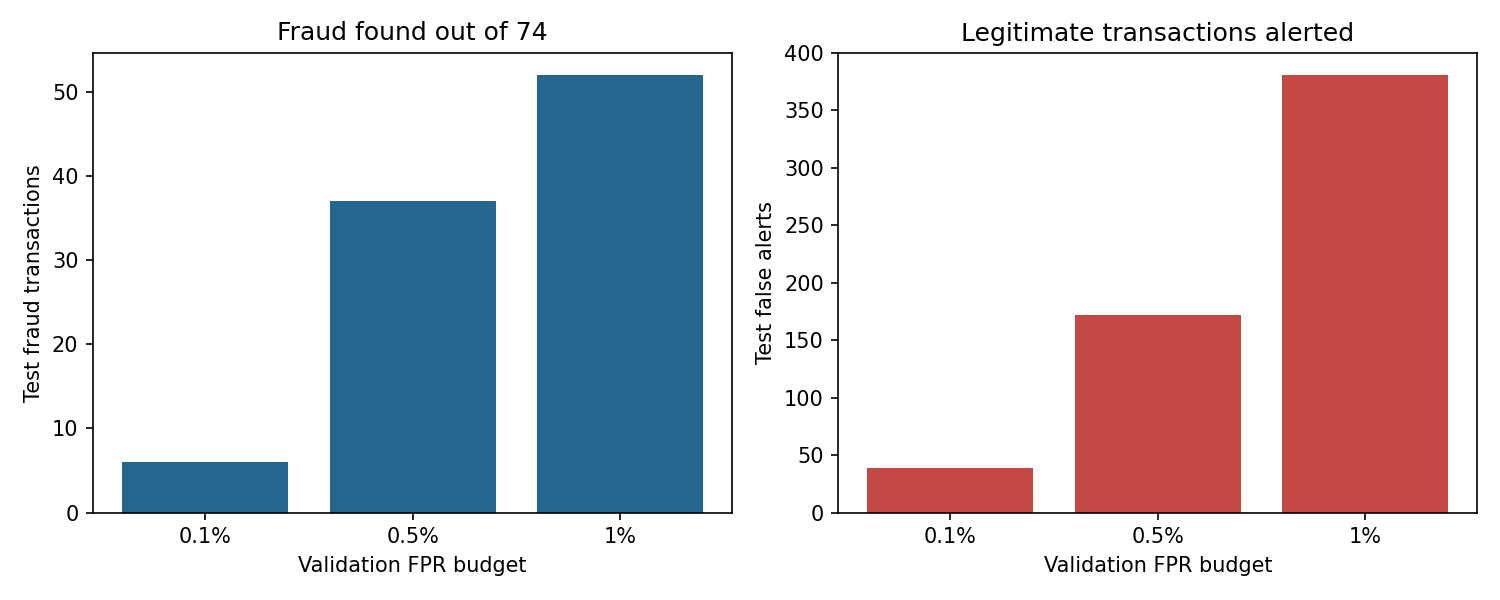

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ["0.1%", "0.5%", "1%"]
axes[0].bar(labels, policy_table["Test fraud found"], color="#24668d")
axes[0].set_title("Fraud found out of 74")
axes[0].set_xlabel("Validation FPR budget")
axes[0].set_ylabel("Test fraud transactions")
axes[1].bar(labels, policy_table["Test false alerts"], color="#c44945")
axes[1].set_title("Legitimate transactions alerted")
axes[1].set_xlabel("Validation FPR budget")
axes[1].set_ylabel("Test false alerts")
plt.tight_layout()
plt.savefig("figures/08_tradeoff.png", dpi=150)
display(Image(filename="figures/08_tradeoff.png", width=800))
plt.close()

**Chart explanation:** Read both panels together. The rightmost policy catches more fraud, but it also asks investigators to review more legitimate transactions. A taller fraud-found bar alone is not enough to decide a useful operating policy.

## 15. Read the precision-recall curve and PR AUC
Our earlier precision and recall used one cutoff. A **precision-recall (PR) curve** shows them across possible cutoffs.

The horizontal axis is recall: move right to find more of the fraud. The vertical axis is precision: higher means fewer wasted alerts as a fraction of the review queue.

**PR AUC** is the area under this curve. We use trapezoidal integration: connect neighboring points with straight lines and add their areas. It summarizes the ranking on this dataset. Larger is better when comparing the same test set. It is not accuracy and is not precision at our chosen cutoff.

The horizontal reference line is the test fraud rate: the precision level associated with an uninformed ranking. We keep only PR AUC in this simpler version, so there is no second area-summary definition to learn.

Test PR AUC (trapezoidal): 0.1496
Test fraud rate: 0.1304%


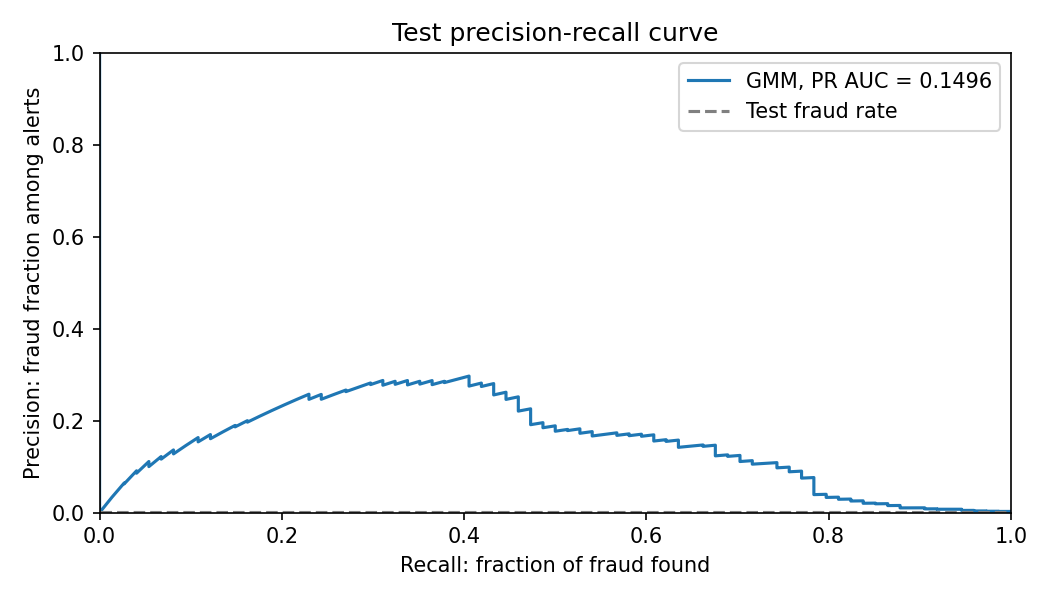

In [21]:
pr_precision, pr_recall, _ = precision_recall_curve(y_test, test_scores)
pr_auc = auc(pr_recall, pr_precision)
test_fraud_rate = y_test.mean()
print(f"Test PR AUC (trapezoidal): {pr_auc:.4f}")
print(f"Test fraud rate: {100*test_fraud_rate:.4f}%")

plt.figure(figsize=(7, 4))
plt.plot(pr_recall, pr_precision, label=f"GMM, PR AUC = {pr_auc:.4f}")
plt.axhline(test_fraud_rate, color="gray", linestyle="--", label="Test fraud rate")
plt.xlabel("Recall: fraction of fraud found")
plt.ylabel("Precision: fraud fraction among alerts")
plt.title("Test precision-recall curve")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig("figures/09_precision_recall.png", dpi=150)
display(Image(filename="figures/09_precision_recall.png", width=800))
plt.close()

**Result:** Test PR AUC is approximately **0.1496**. The curve shows how alert quality changes as recall changes. This number does **not** mean we catch 14.96% of fraud; at the default cutoff, recall is 50%.

The conventional PR endpoint at zero recall can have precision 1 even though no transactions are reviewed there. It does not mean our highest-scoring transaction is guaranteed to be fraud.

## 16. What if investigators can review only 100 transactions?
This is a **capacity rule**: sort the test transactions by score and take exactly the first 100. It differs from a threshold rule, which can produce any number of alerts.

`argsort` gives row positions sorted by score. The minus sign puts larger scores first. `[:100]` keeps the first 100 positions. Stable sorting keeps the existing time order when scores tie.

This is 100 reviews for the **whole test batch**, not a daily review-rate claim.

Frauds among the 100 reviewed: 29
Precision@100: 29%


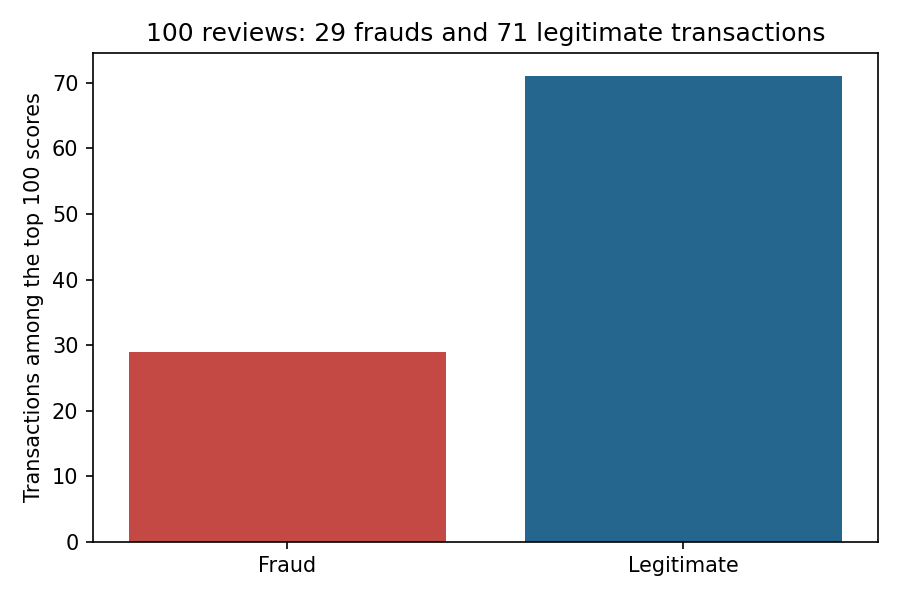

In [22]:
ranked_positions = np.argsort(-test_scores, kind="stable")
top_100_positions = ranked_positions[:100]
frauds_in_100 = int(y_test[top_100_positions].sum())
precision_at_100 = frauds_in_100 / 100

print("Frauds among the 100 reviewed:", frauds_in_100)
print(f"Precision@100: {100*precision_at_100:.0f}%")

plt.figure(figsize=(6, 4))
plt.bar(["Fraud", "Legitimate"], [frauds_in_100, 100-frauds_in_100], color=["#c44945", "#24668d"])
plt.ylabel("Transactions among the top 100 scores")
plt.title("100 reviews: 29 frauds and 71 legitimate transactions")
plt.tight_layout()
plt.savefig("figures/10_capacity.png", dpi=150)
display(Image(filename="figures/10_capacity.png", width=800))
plt.close()

**Result:** We find 29 frauds among 100 reviews, so **precision@100 = 29%**. The other 71 are legitimate. The default threshold found 37 frauds with 209 reviews, so these two policies have different workloads.

## 17. Save the small set of results
These lines save the tables used by the report and slides. They do not train another model or change our decisions. `to_csv` writes a table; `json.dumps` writes a small collection of named results.

In [23]:
split_table.to_csv("results/splits.csv", index=False)
selection.to_csv("results/gmm_selection.csv", index=False)
policy_table.to_csv("results/threshold_results.csv", index=False)

summary = {
    "raw_rows": raw_rows, "raw_frauds": raw_frauds, "duplicates_removed": repeated_rows,
    "clean_rows": len(df), "clean_frauds": int(df["Class"].sum()),
    "selected_K": best_k, "default_threshold": default_threshold,
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    "recall": float(recall_default), "precision": float(precision_default),
    "test_FPR": float(fpr_default), "PR_AUC": float(pr_auc),
    "precision_at_100": float(precision_at_100)
}
Path("results/summary.json").write_text(json.dumps(summary, indent=2))
print("Saved the results.")

Saved the results.


## 18. Explain the project in six sentences
1. We want to help people decide which card transactions to review first.
2. We learn normal patterns from 169,893 legitimate training transactions.
3. We use 29 inputs, fit four GMMs, and select K=8 using the smallest training BIC.
4. We give less typical transactions a higher score and choose alert cutoffs using validation data.
5. The default cutoff finds 37 of 74 test frauds with 172 false alerts; the top 100 scores contain 29 frauds.
6. The model makes mistakes, and the data is too limited to claim it will work the same way in a real bank.

## What are the important limits?
- **Unusual does not always mean fraud.** This explains false alerts and missed fraud.
- **Only 74 test frauds.** One different fraud decision changes recall by about 1.35 percentage points.
- **Old, short dataset with hidden feature meanings.** It cannot establish current bank performance. We cannot inspect the provider's original PCA fitting.
- **Simplified model and small K search.** Diagonal covariance misses some relationships, and eight is only the best K we tried.
- **Cleaning assumption.** We remove exact repeated rows without transaction IDs to prove their identity.
- **Future patterns can change.** A validation false-alert budget does not guarantee the same rate later.

## Short literature review
| Source | What we learn | Where we use it |
|---|---|---|
| Dempster, Laird and Rubin (1977) | EM alternates estimated memberships and parameter updates | GMM training |
| Saito and Rehmsmeier (2015) | PR measures help expose false-alert burden with rare positives | Evaluation |
| scikit-learn mixture documentation | GMM settings and AIC/BIC selection | Implementation |
| ULB/Worldline dataset and TensorFlow mirror documentation | Data source and column context | Dataset |

These sources explain our method. Our results come from the run above, not numbers copied from a paper.

## Sources
- [Dempster, Laird and Rubin (1977): EM](https://doi.org/10.1111/j.2517-6161.1977.tb01600.x)
- [Saito and Rehmsmeier (2015): precision-recall evaluation](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432)
- [scikit-learn: Gaussian mixtures](https://scikit-learn.org/stable/modules/mixture.html)
- [ULB/Worldline dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- [TensorFlow: documented data mirror](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data)
- Supplied course instructions, page 2: Phase 1 evaluates machine learning; the viva assesses each student individually.

The report and slides use these same choices and results. The autoencoder is reserved for Phase 2. See `STUDY_GUIDE.md` for a short glossary, worked examples and viva questions.